Install / import dependencies

In [1]:
%pip install -U ultralytics pyyaml

Note: you may need to restart the kernel to use updated packages.


In [2]:
import torch
from ultralytics import YOLO

assert torch.cuda.is_available(), "CUDA GPU is unavailable!"

print("GPU:", torch.cuda.get_device_name(0))
print("Ultralytics:", __import__("ultralytics").__version__)

model = YOLO("yolo11n.yaml")  # Build from scratch
print("Model created successfully.")

GPU: NVIDIA GeForce RTX 4060 Laptop GPU
Ultralytics: 8.4.192
Model created successfully.


In [3]:
from pathlib import Path
import yaml
import torch
import ultralytics
from ultralytics import YOLO

PROJECT = Path(r"C:\Projects\smoke_vehicle_detection")
DATASET_DIR = PROJECT / "EcoWatch-Final-YOLO"
DATA_YAML = DATASET_DIR / "data.yaml"
RUNS_DIR = PROJECT / "runs" / "ecowatch"

print("Ultralytics:", ultralytics.__version__)
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU unavailable; training will run on CPU.")
print("Dataset YAML exists:", DATA_YAML.exists())

if not DATA_YAML.exists():
    raise FileNotFoundError(f"Could not find {DATA_YAML}. Check the dataset folder path.")

Ultralytics: 8.4.192
PyTorch: 2.6.0+cu124
CUDA available: True
GPU: NVIDIA GeForce RTX 4060 Laptop GPU
Dataset YAML exists: True


Check the dataset configuration

In [4]:
with DATA_YAML.open("r", encoding="utf-8") as f:
    config = yaml.safe_load(f)

print(yaml.safe_dump(config, sort_keys=False))

assert config.get("nc") == 1, "Expected exactly one class."
names = config.get("names")
if isinstance(names, dict):
    class_names = list(names.values())
else:
    class_names = list(names or [])

assert class_names == ["smoke"], f"Expected ['smoke'], got {class_names}"

for split in ["train", "val", "test"]:
    split_rel = config.get(split)
    if split_rel:
        split_path = Path(config.get("path", DATASET_DIR)) / split_rel
        print(f"{split}: {split_path} | exists={split_path.exists()}")
        if not split_path.exists():
            raise FileNotFoundError(f"Missing {split} images folder: {split_path}")

path: C:\Projects\smoke_vehicle_detection\EcoWatch-Final-YOLO
train: train/images
val: valid/images
test: test/images
names:
  0: smoke
nc: 1

train: C:\Projects\smoke_vehicle_detection\EcoWatch-Final-YOLO\train\images | exists=True
val: C:\Projects\smoke_vehicle_detection\EcoWatch-Final-YOLO\valid\images | exists=True
test: C:\Projects\smoke_vehicle_detection\EcoWatch-Final-YOLO\test\images | exists=True


Train YOLO11n from scratch

In [5]:
RUN_NAME = "yolo11n_smoke_scratch"
RUN_DIR = RUNS_DIR / RUN_NAME

if RUN_DIR.exists():
    raise FileExistsError(
        f"Run folder already exists: {RUN_DIR}\n"
        "Rename RUN_NAME or move/backup the existing folder before starting another run."
    )

# Load architecture only; do not load a pretrained checkpoint.
model = YOLO("yolo11n.yaml")

train_results = model.train(
    data=str(DATA_YAML),
    epochs=50,
    imgsz=640,
    batch=8,
    device=0 if torch.cuda.is_available() else "cpu",
    workers=4,
    pretrained=False,
    seed=42,
    deterministic=True,
    patience=15,
    project=str(RUNS_DIR),
    name=RUN_NAME,
    exist_ok=False,
    plots=True,
    save=True,
    verbose=True,
)

BEST_MODEL = RUN_DIR / "weights" / "best.pt"
LAST_MODEL = RUN_DIR / "weights" / "last.pt"

print("Training completed.")
print("Best model:", BEST_MODEL, "| exists:", BEST_MODEL.exists())
print("Last model:", LAST_MODEL, "| exists:", LAST_MODEL.exists())
print("Results CSV:", RUN_DIR / "results.csv")

Ultralytics 8.4.192  Python-3.13.5 torch-2.6.0+cu124 CUDA:0 (NVIDIA GeForce RTX 4060 Laptop GPU, 8188MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=C:\Projects\smoke_vehicle_detection\EcoWatch-Final-YOLO\data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.yaml, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=

Evaluate on the held-out test split

In [7]:
if not BEST_MODEL.exists():
    raise FileNotFoundError(
        f"Best checkpoint not found: {BEST_MODEL}. Run the training cell first."
    )

best_model = YOLO(str(BEST_MODEL))

test_metrics = best_model.val(
    data=str(DATA_YAML),
    split='test',
    imgsz=640,
    batch=8,
    device=0
    if torch.cuda.is_available()
    else "cpu",
        plots=True,
        project=str(RUNS_DIR),
        name="test_evaluation",
)

print(test_metrics)

Ultralytics 8.4.192  Python-3.13.5 torch-2.6.0+cu124 CUDA:0 (NVIDIA GeForce RTX 4060 Laptop GPU, 8188MiB)
YOLO11n summary (fused): 100 layers, 2,582,347 parameters, 0 gradients, 6.4 GFLOPs
WARNING val: Slow image access detected (ping: 0.2±0.1 ms, read: 3.8±0.9 MB/s, size: 30.9 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning C:\Projects\smoke_vehicle_detection\EcoWatch-Final-YOLO\test\labels... 225 images, 164 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 225/225 810.7it/s 0.3s0.1s
val: New cache created: C:\Projects\smoke_vehicle_detection\EcoWatch-Final-YOLO\test\labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 29/29 1.5it/s 19.8s<0.1s
                   all        225         69      0.769      0.578      0.736      0.334
Speed: 1.3ms preprocess, 3.4ms inference, 0.0ms loss, 0.6ms postprocess per image
Results 

Run a prediction on a smoke image

In [8]:
# Update this to a real image path from EcoWatch-Final-YOLO/train/images
SAMPLE_IMAGE = DATASET_DIR / "train" / "images" / "smoke_000009_jpg.rf.f5d6587e530837e6787b0ef062c2d23c.jpg"

if not SAMPLE_IMAGE.exists():
    print("Update SAMPLE_IMAGE to an existing image path before running prediction.")
else:
    prediction_model = YOLO(str(BEST_MODEL))
    prediction_model.predict(
        source=str(SAMPLE_IMAGE),
        imgsz=640,
        conf=0.25,
        save=True,
        project=str(RUNS_DIR),
        name="sample_prediction",
    )
    print("Prediction saved under:", RUNS_DIR / "sample_prediction")


image 1/1 C:\Projects\smoke_vehicle_detection\EcoWatch-Final-YOLO\train\images\smoke_000009_jpg.rf.f5d6587e530837e6787b0ef062c2d23c.jpg: 640x640 2 smokes, 7.4ms
Speed: 1.8ms preprocess, 7.4ms inference, 2.0ms postprocess per image at shape (1, 3, 640, 640)
Results saved to C:\Projects\smoke_vehicle_detection\runs\ecowatch\sample_prediction
Prediction saved under: C:\Projects\smoke_vehicle_detection\runs\ecowatch\sample_prediction


test the trained model on real images

In [9]:
from pathlib import Path
from ultralytics import YOLO

PROJECT = Path(r"C:\Projects\smoke_vehicle_detection")

best_path = (
    PROJECT / "runs" / "ecowatch" /
    "yolo11n_smoke_scratch" / "weights" / "best.pt"
)

assert best_path.exists(), f"Model not found: {best_path}"

model = YOLO(str(best_path))

# Replace this with the path to a real test image.
image_path = Path(
    r"C:\Projects\smoke_vehicle_detection\EcoWatch-Final-YOLO\test\images\smoke_1-5-_jpeg_jpg.rf.3ed35671430b6ba56af6de75e65fdadf.jpg"
)

assert image_path.exists(), f"Image not found: {image_path}"

results = model.predict(
    source=str(image_path),
    device=0,
    imgsz=640,
    conf=0.25,
    save=True
)

print("Prediction complete.")
print("Results saved under the runs directory.")


image 1/1 C:\Projects\smoke_vehicle_detection\EcoWatch-Final-YOLO\test\images\smoke_1-5-_jpeg_jpg.rf.3ed35671430b6ba56af6de75e65fdadf.jpg: 640x640 1 smoke, 7.0ms
Speed: 4.8ms preprocess, 7.0ms inference, 1.4ms postprocess per image at shape (1, 3, 640, 640)
Results saved to C:\Projects\smoke_vehicle_detection\notebooks\runs\detect\predict
Prediction complete.
Results saved under the runs directory.


### Create a smoke detection

In [10]:
from pathlib import Path
import random
from ultralytics import YOLO

PROJECT = Path(r"C:\Projects\smoke_vehicle_detection")
DATASET = PROJECT / "EcoWatch-Final-YOLO"
TEST_IMAGES = DATASET / "test" / "images"
TEST_LABELS = DATASET / "test" / "labels"

BEST_MODEL = (
    PROJECT / "runs" / "ecowatch" /
    "yolo11n_smoke_scratch" / "weights" / "best.pt"
)

assert BEST_MODEL.exists(), f"Model not found: {BEST_MODEL}"
assert TEST_IMAGES.exists(), f"Images not found: {TEST_IMAGES}"
assert TEST_LABELS.exists(), f"Labels not found: {TEST_LABELS}"

model = YOLO(str(BEST_MODEL))

extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
images = [
    p for p in TEST_IMAGES.iterdir()
    if p.suffix.lower() in extensions
]

positive, negative = [], []

for image_path in images:
    label_path = TEST_LABELS / f"{image_path.stem}.txt"

    if not label_path.exists():
        continue

    if label_path.stat().st_size > 0:
        positive.append(image_path)
    else:
        negative.append(image_path)

random.seed(42)
selected_positive = random.sample(positive, min(3, len(positive)))
selected_negative = random.sample(negative, min(3, len(negative)))

print(f"Smoke-labelled images available: {len(positive)}")
print(f"Empty-label images available: {len(negative)}")
print("\nSelected smoke images:")
for p in selected_positive:
    print(p.name)

print("\nSelected no-smoke images:")
for p in selected_negative:
    print(p.name)

selected = selected_positive + selected_negative

if not selected:
    raise RuntimeError("No labelled test images were found.")

results = model.predict(
    source=[str(p) for p in selected],
    device=0,
    imgsz=640,
    conf=0.25,
    save=True,
    project=str(PROJECT / "runs" / "ecowatch"),
    name="smoke_error_analysis",
    exist_ok=True
)

print("\nPredictions saved to:")
print(PROJECT / "runs" / "ecowatch" / "smoke_error_analysis")


Smoke-labelled images available: 61
Empty-label images available: 164

Selected smoke images:
smoke_100031_jpg.rf.c04855f7a1fe64e168649343d76feaac.jpg
smoke_000167_jpg.rf.5aef4ea76846f2b9e6dc9b2040618ba3.jpg
smoke_000118_jpg.rf.437e5f1630f39c8806ba65b310e0161e.jpg

Selected no-smoke images:
negative_319633181_666419058496399_1502378893227541031_n_jpg.rf.3fd8b6fd4821df36540ceede136391f4.jpg
negative_319533445_490938599803316_5665417024914267410_n_jpg.rf.ff2ffed2d183069beb8cd07dfe74fee2.jpg
negative_319186109_2804873319647120_6384269014082541575_n_jpg.rf.523f69eea79487bc812a8f3eb2431799.jpg

0: 640x640 1 smoke, 2.0ms
1: 640x640 (no detections), 2.0ms
2: 640x640 (no detections), 2.0ms
3: 640x640 (no detections), 2.0ms
4: 640x640 (no detections), 2.0ms
5: 640x640 (no detections), 2.0ms
Speed: 5.3ms preprocess, 2.0ms inference, 0.6ms postprocess per image at shape (1, 3, 640, 640)
Results saved to C:\Projects\smoke_vehicle_detection\runs\ecowatch\smoke_error_analysis

Predictions saved to:


In [12]:

from pathlib import Path
from ultralytics import YOLO

PROJECT = Path(r"C:\Projects\smoke_vehicle_detection")
BEST_MODEL = (
    PROJECT / "runs" / "ecowatch" /
    "yolo11n_smoke_scratch" / "weights" / "best.pt"
)
TEST_IMAGES = PROJECT / "EcoWatch-Final-YOLO" / "test" / "images"

model = YOLO(str(BEST_MODEL))

# Select three smoke-labelled and three empty-label images again.
TEST_LABELS = PROJECT / "EcoWatch-Final-YOLO" / "test" / "labels"
extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

smoke_images, empty_images = [], []

for image in sorted(TEST_IMAGES.iterdir()):
    if image.suffix.lower() not in extensions:
        continue

    label = TEST_LABELS / f"{image.stem}.txt"
    if not label.exists():
        continue

    if label.stat().st_size > 0:
        smoke_images.append(image)
    else:
        empty_images.append(image)

# Deterministic selection, matching the earlier test.
import random
random.seed(42)
selected = (
    random.sample(smoke_images, min(3, len(smoke_images))) +
    random.sample(empty_images, min(3, len(empty_images)))
)

for image in selected:
    print(f"\nIMAGE: {image.name}")

    for threshold in (0.10, 0.25, 0.50):
        result = model.predict(
            source=str(image),
            device=0,
            imgsz=640,
            conf=threshold,
            save=False,
            verbose=False
        )[0]

        scores = result.boxes.conf.tolist()
        scores = [round(float(s), 3) for s in scores]

        print(
            f"  conf={threshold:.2f}: "
            f"{len(scores)} detection(s), scores={scores}"
        )



IMAGE: smoke_100031_jpg.rf.c04855f7a1fe64e168649343d76feaac.jpg
  conf=0.10: 3 detection(s), scores=[0.288, 0.246, 0.101]
  conf=0.25: 1 detection(s), scores=[0.288]
  conf=0.50: 0 detection(s), scores=[]

IMAGE: smoke_000167_jpg.rf.5aef4ea76846f2b9e6dc9b2040618ba3.jpg
  conf=0.10: 0 detection(s), scores=[]
  conf=0.25: 0 detection(s), scores=[]
  conf=0.50: 0 detection(s), scores=[]

IMAGE: smoke_000118_jpg.rf.437e5f1630f39c8806ba65b310e0161e.jpg
  conf=0.10: 2 detection(s), scores=[0.204, 0.101]
  conf=0.25: 0 detection(s), scores=[]
  conf=0.50: 0 detection(s), scores=[]

IMAGE: negative_319633181_666419058496399_1502378893227541031_n_jpg.rf.3fd8b6fd4821df36540ceede136391f4.jpg
  conf=0.10: 0 detection(s), scores=[]
  conf=0.25: 0 detection(s), scores=[]
  conf=0.50: 0 detection(s), scores=[]

IMAGE: negative_319533445_490938599803316_5665417024914267410_n_jpg.rf.ff2ffed2d183069beb8cd07dfe74fee2.jpg
  conf=0.10: 0 detection(s), scores=[]
  conf=0.25: 0 detection(s), scores=[]
  con

In [13]:

from pathlib import Path
from ultralytics import YOLO

PROJECT = Path(r"C:\Projects\smoke_vehicle_detection")

model = YOLO(
    str(PROJECT / "runs" / "ecowatch" /
        "yolo11n_smoke_scratch" / "weights" / "best.pt")
)

TEST_IMAGES = PROJECT / "EcoWatch-Final-YOLO" / "test" / "images"

filenames = [
    "smoke_100031_jpg.rf.c04855f7a1fe64e168649343d76feaac.jpg",
    "smoke_000167_jpg.rf.5aef4ea76846f2b9e6dc9b2040618ba3.jpg",
    "smoke_000118_jpg.rf.437e5f1630f39c8806ba65b310e0161e.jpg",
]

paths = [TEST_IMAGES / name for name in filenames]

for path in paths:
    assert path.exists(), f"Image not found: {path}"

model.predict(
    source=[str(path) for path in paths],
    device=0,
    imgsz=640,
    conf=0.10,
    save=True,
    project=str(PROJECT / "runs" / "ecowatch"),
    name="smoke_low_confidence_review",
    exist_ok=True
)

print("Saved predictions to:")
print(PROJECT / "runs" / "ecowatch" / "smoke_low_confidence_review")



0: 640x640 3 smokes, 11.6ms
1: 640x640 (no detections), 11.6ms
2: 640x640 2 smokes, 11.6ms
Speed: 2.3ms preprocess, 11.6ms inference, 0.8ms postprocess per image at shape (1, 3, 640, 640)
Results saved to C:\Projects\smoke_vehicle_detection\runs\ecowatch\smoke_low_confidence_review
Saved predictions to:
C:\Projects\smoke_vehicle_detection\runs\ecowatch\smoke_low_confidence_review


inspect the original labels


smoke_100031_jpg.rf.c04855f7a1fe64e168649343d76feaac.jpg
Label file exists: True
Annotation rows: 1

smoke_000167_jpg.rf.5aef4ea76846f2b9e6dc9b2040618ba3.jpg
Label file exists: True
Annotation rows: 1

smoke_000118_jpg.rf.437e5f1630f39c8806ba65b310e0161e.jpg
Label file exists: True
Annotation rows: 1


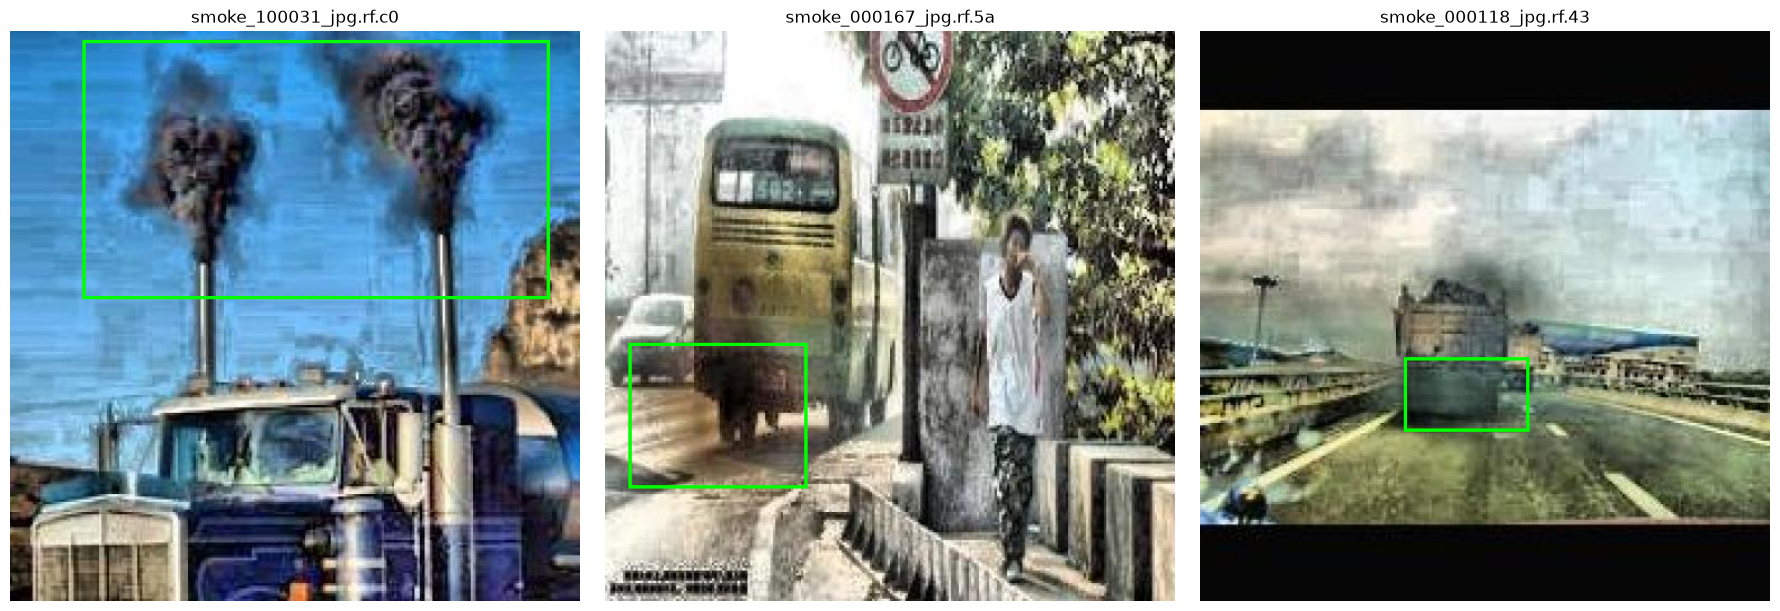

In [14]:

from pathlib import Path
from PIL import Image, ImageDraw
import matplotlib.pyplot as plt

PROJECT = Path(r"C:\Projects\smoke_vehicle_detection")
IMAGE_DIR = PROJECT / "EcoWatch-Final-YOLO" / "test" / "images"
LABEL_DIR = PROJECT / "EcoWatch-Final-YOLO" / "test" / "labels"

filenames = [
    "smoke_100031_jpg.rf.c04855f7a1fe64e168649343d76feaac.jpg",
    "smoke_000167_jpg.rf.5aef4ea76846f2b9e6dc9b2040618ba3.jpg",
    "smoke_000118_jpg.rf.437e5f1630f39c8806ba65b310e0161e.jpg",
]

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for ax, filename in zip(axes, filenames):
    image_path = IMAGE_DIR / filename
    label_path = LABEL_DIR / f"{Path(filename).stem}.txt"

    image = Image.open(image_path).convert("RGB")
    draw = ImageDraw.Draw(image)
    width, height = image.size

    print(f"\n{filename}")
    print("Label file exists:", label_path.exists())

    if label_path.exists():
        lines = label_path.read_text().splitlines()
        print("Annotation rows:", len(lines))

        for line in lines:
            parts = line.split()
            if len(parts) != 5:
                print("Unexpected annotation format:", line)
                continue

            class_id, xc, yc, bw, bh = map(float, parts)
            x1 = (xc - bw / 2) * width
            y1 = (yc - bh / 2) * height
            x2 = (xc + bw / 2) * width
            y2 = (yc + bh / 2) * height

            draw.rectangle((x1, y1, x2, y2), outline="lime", width=3)

    ax.imshow(image)
    ax.set_title(Path(filename).name[:22])
    ax.axis("off")

plt.tight_layout()
plt.show()


In [15]:

from pathlib import Path
from PIL import Image, ImageDraw
import random
import math

PROJECT = Path(r"C:\Projects\smoke_vehicle_detection")
DATASET = PROJECT / "EcoWatch-Final-YOLO"

IMAGE_DIR = DATASET / "train" / "images"
LABEL_DIR = DATASET / "train" / "labels"
OUTPUT_DIR = PROJECT / "annotation_audit"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
SAMPLE_SIZE = 48
IMAGES_PER_SHEET = 16
THUMB_SIZE = (320, 260)

random.seed(42)

# Collect images that have at least one annotation.
annotated_images = []

for image_path in IMAGE_DIR.iterdir():
    if image_path.suffix.lower() not in IMAGE_EXTENSIONS:
        continue

    label_path = LABEL_DIR / f"{image_path.stem}.txt"

    if label_path.exists() and label_path.stat().st_size > 0:
        annotated_images.append(image_path)

if not annotated_images:
    raise RuntimeError("No annotated training images were found.")

selected = random.sample(
    annotated_images,
    min(SAMPLE_SIZE, len(annotated_images))
)

def draw_ground_truth(image_path):
    image = Image.open(image_path).convert("RGB")
    draw = ImageDraw.Draw(image)

    label_path = LABEL_DIR / f"{image_path.stem}.txt"
    width, height = image.size

    for line in label_path.read_text().splitlines():
        parts = line.split()

        if len(parts) != 5:
            continue

        class_id, xc, yc, bw, bh = map(float, parts)

        x1 = (xc - bw / 2) * width
        y1 = (yc - bh / 2) * height
        x2 = (xc + bw / 2) * width
        y2 = (yc + bh / 2) * height

        draw.rectangle(
            (x1, y1, x2, y2),
            outline="lime",
            width=max(2, width // 250)
        )

    return image

for start in range(0, len(selected), IMAGES_PER_SHEET):
    batch = selected[start:start + IMAGES_PER_SHEET]

    cols = 4
    rows = math.ceil(len(batch) / cols)
    sheet = Image.new(
        "RGB",
        (cols * THUMB_SIZE[0], rows * (THUMB_SIZE[1] + 35)),
        "white"
    )

    sheet_draw = ImageDraw.Draw(sheet)

    for i, image_path in enumerate(batch):
        image = draw_ground_truth(image_path)
        image.thumbnail(THUMB_SIZE)

        x = (i % cols) * THUMB_SIZE[0]
        y = (i // cols) * (THUMB_SIZE[1] + 35)

        sheet.paste(image, (x, y))
        sheet_draw.text(
            (x + 4, y + THUMB_SIZE[1] + 5),
            image_path.name[:42],
            fill="black"
        )

    sheet_number = start // IMAGES_PER_SHEET + 1
    output_path = OUTPUT_DIR / f"train_annotation_review_{sheet_number:02d}.jpg"
    sheet.save(output_path, quality=92)

    print("Saved:", output_path)

print(f"\nAnnotated training images available: {len(annotated_images)}")
print(f"Images selected for review: {len(selected)}")
print("Review folder:", OUTPUT_DIR)


Saved: C:\Projects\smoke_vehicle_detection\annotation_audit\train_annotation_review_01.jpg
Saved: C:\Projects\smoke_vehicle_detection\annotation_audit\train_annotation_review_02.jpg
Saved: C:\Projects\smoke_vehicle_detection\annotation_audit\train_annotation_review_03.jpg

Annotated training images available: 2655
Images selected for review: 48
Review folder: C:\Projects\smoke_vehicle_detection\annotation_audit


In [16]:

from pathlib import Path
from ultralytics import YOLO
import torch

PROJECT = Path(r"C:\Projects\smoke_vehicle_detection")

MODEL_PATH = (
    PROJECT / "runs" / "ecowatch"
    / "yolo11n_smoke_scratch" / "weights" / "best.pt"
)

# Replace this with the path to your video.
VIDEO_PATH = PROJECT / 'test_video' / "test_video.mp4"

OUTPUT_DIR = PROJECT / "runs" / "ecowatch" / "video_detection"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

if not MODEL_PATH.exists():
    raise FileNotFoundError(f"Model not found: {MODEL_PATH}")

if not VIDEO_PATH.exists():
    raise FileNotFoundError(
        f"Video not found: {VIDEO_PATH}\n"
        "Change VIDEO_PATH to your actual video file."
    )

device = 0 if torch.cuda.is_available() else "cpu"
model = YOLO(str(MODEL_PATH))

results = model.predict(
    source=str(VIDEO_PATH),
    conf=0.25,
    imgsz=640,
    device=device,
    save=True,
    project=str(OUTPUT_DIR),
    name="video_result",
    exist_ok=True,
    stream=True,
    verbose=False
)

frame_count = 0
frames_with_smoke = 0

for result in results:
    frame_count += 1

    if result.boxes is not None and len(result.boxes) > 0:
        frames_with_smoke += 1

print("Video processing completed.")
print("Frames processed:", frame_count)
print("Frames with smoke detections:", frames_with_smoke)
print("Annotated video folder:", OUTPUT_DIR / "video_result")


Results saved to C:\Projects\smoke_vehicle_detection\runs\ecowatch\video_detection\video_result
Video processing completed.
Frames processed: 257
Frames with smoke detections: 5
Annotated video folder: C:\Projects\smoke_vehicle_detection\runs\ecowatch\video_detection\video_result
